# Instalar mi paquete

In [ ]:
%pip install -q "git+https://github.com/adbaldel/Complex-Dynamics-Thesis.git#subdirectory=python"

In [ ]:
%pip install -q --upgrade "IPython>=9.17" "pyvista>=0.48.4"

# Imports

In [1]:
import complex_dynamics.calculator as dcalc
import complex_dynamics.plot as dplot
import matplotlib.pyplot as plt
import numpy as np
from complex_dynamics.rational_map import RationalMap

In [ ]:
import pyvista as pv

pv.set_jupyter_backend("html")

# Ejemplo del libro (Möbius Transformation)

## Comprobación de que eligiendo $\epsilon$ negativo y pequeño, inicialmente diverge

In [3]:
R = RationalMap.from_latex(r"\frac{3z - 2}{2z - 1}")
print(R)

\frac{3 z - 2}{2 z - 1}


In [4]:
epsilon = -0.01
zeta = 1

z0 = np.complex128(zeta + epsilon)

In [5]:
max_iterations = 50
orbit = dcalc.calculate_forward_orbit(z0, R=R, max_iterations=max_iterations)

Me ha parecido curioso que de repente explote y se vaya al $-1.5 \cdot 10^{11}$

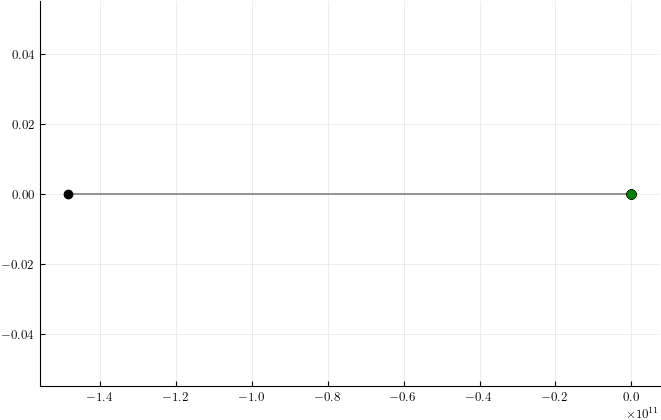

In [6]:
fig, ax = dplot.plot_orbit(orbit)

Para que se vea bien los puntos por los que pasa he decidido mostrarlos como una ristra de números (en vez de en una gráfica)}

In [7]:
index = 1
for z in orbit:
    print(index, ":\t", z)
    index += 1

1 :	 (0.99+0j)
2 :	 (0.9897959183673467+0j)
3 :	 (0.9895833333333333+0j)
4 :	 (0.9893617021276597+0j)
5 :	 (0.9891304347826089+0j)
6 :	 (0.9888888888888892+0j)
7 :	 (0.9886363636363642+0j)
8 :	 (0.9883720930232563+0j)
9 :	 (0.9880952380952387+0j)
10 :	 (0.9878048780487811+0j)
11 :	 (0.9875000000000008+0j)
12 :	 (0.9871794871794882+0j)
13 :	 (0.9868421052631592+0j)
14 :	 (0.9864864864864877+0j)
15 :	 (0.9861111111111125+0j)
16 :	 (0.9857142857142871+0j)
17 :	 (0.9852941176470602+0j)
18 :	 (0.9848484848484863+0j)
19 :	 (0.9843750000000017+0j)
20 :	 (0.9838709677419372+0j)
21 :	 (0.983333333333335+0j)
22 :	 (0.9827586206896567+0j)
23 :	 (0.9821428571428589+0j)
24 :	 (0.9814814814814833+0j)
25 :	 (0.9807692307692328+0j)
26 :	 (0.9800000000000025+0j)
27 :	 (0.9791666666666693+0j)
28 :	 (0.9782608695652203+0j)
29 :	 (0.9772727272727304+0j)
30 :	 (0.9761904761904799+0j)
31 :	 (0.9750000000000043+0j)
32 :	 (0.9736842105263207+0j)
33 :	 (0.9722222222222276+0j)
34 :	 (0.9705882352941237+0j)
35 :

Se puede ver con más zoom que las primeras iteraciones diverge

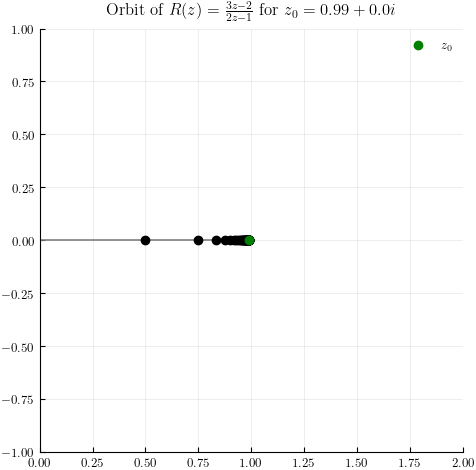

In [8]:
center = complex(1, 0)
max_distance_to_center = 1

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

title = rf"Orbit of $R(z) = \frac{{3z - 2}}{{2z - 1}}$ for $z_0 = {round(z0.real, 2)} + {round(z0.imag, 2)}i$"

ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()
fig.tight_layout()
fig

## Comprobación de que eventualmente converge

Si cogemos suficientes iteraciones (de hecho después de irse al $-10^{12}$ vuelve al $1.5$), se ve como sigue convergiendo al $1$ cómo hemos probado a mano

In [9]:
max_iterations = 100
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

Aquí se pueden ver las primeras iteraciones que van hacia la izquierda alejándose del $1$, pero después vuelve por la derecha

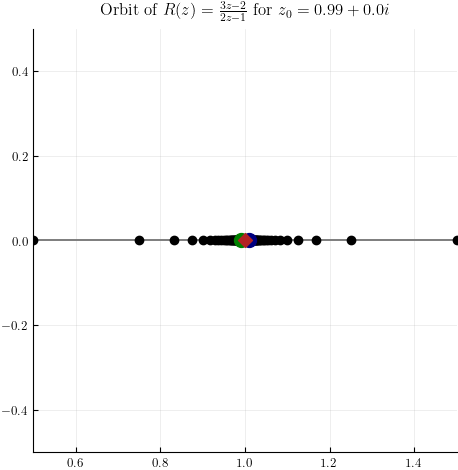

In [10]:
center = complex(1, 0)
max_distance_to_center = 0.5

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

title = rf"Orbit of $R(z) = \frac{{3z - 2}}{{2z - 1}}$ for $z_0 = {round(z0.real, 2)} + {round(z0.imag, 2)}i$"

fig, ax = dplot.plot_orbit(orbit)
ax.scatter(orbit[0].real, orbit[0].imag, color="green", s=100, zorder=3)
ax.scatter(
    orbit[-1].real,
    orbit[-1].imag,
    label=rf"$z_{max_iterations}$",
    color="navy",
    s=100,
    zorder=3,
)
ax.scatter(
    1, 0, label=r"$\zeta = 1$", marker="D", color="firebrick", s=50, zorder=4
)
ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.grid(True)
ax.set_aspect("equal")
fig.tight_layout()

In [11]:
plotter = dplot.plot_orbit_on_dynamic_sphere(orbit, show=True)

Widget(value='<iframe src="http://localhost:40675/index.html?ui=P_0x7f2174ba8cd0_0&reconnect=auto" class="pyvi…

Para que se vea bien los puntos por los que pasa he decidido mostrarlos como una ristra de números (en vez de en una gráfica)

In [12]:
i = 1
for z in orbit:
    print(i, ":\t", z)
    i += 1

1 :	 (0.99+0j)
2 :	 (0.9897959183673467+0j)
3 :	 (0.9895833333333333+0j)
4 :	 (0.9893617021276597+0j)
5 :	 (0.9891304347826089+0j)
6 :	 (0.9888888888888892+0j)
7 :	 (0.9886363636363642+0j)
8 :	 (0.9883720930232563+0j)
9 :	 (0.9880952380952387+0j)
10 :	 (0.9878048780487811+0j)
11 :	 (0.9875000000000008+0j)
12 :	 (0.9871794871794882+0j)
13 :	 (0.9868421052631592+0j)
14 :	 (0.9864864864864877+0j)
15 :	 (0.9861111111111125+0j)
16 :	 (0.9857142857142871+0j)
17 :	 (0.9852941176470602+0j)
18 :	 (0.9848484848484863+0j)
19 :	 (0.9843750000000017+0j)
20 :	 (0.9838709677419372+0j)
21 :	 (0.983333333333335+0j)
22 :	 (0.9827586206896567+0j)
23 :	 (0.9821428571428589+0j)
24 :	 (0.9814814814814833+0j)
25 :	 (0.9807692307692328+0j)
26 :	 (0.9800000000000025+0j)
27 :	 (0.9791666666666693+0j)
28 :	 (0.9782608695652203+0j)
29 :	 (0.9772727272727304+0j)
30 :	 (0.9761904761904799+0j)
31 :	 (0.9750000000000043+0j)
32 :	 (0.9736842105263207+0j)
33 :	 (0.9722222222222276+0j)
34 :	 (0.9705882352941237+0j)
35 :

## Generación de puntos iniciales cerca del $1$ aleatorios para ver diferentes comportamientos

In [13]:
radius = 0.5
r_real = np.random.uniform(-radius, radius)
r_imag = np.random.uniform(-radius, radius)
r = complex(r_real, r_imag)
zeta = 1

z0 = np.complex128(zeta + r)

In [14]:
max_iterations = 100
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

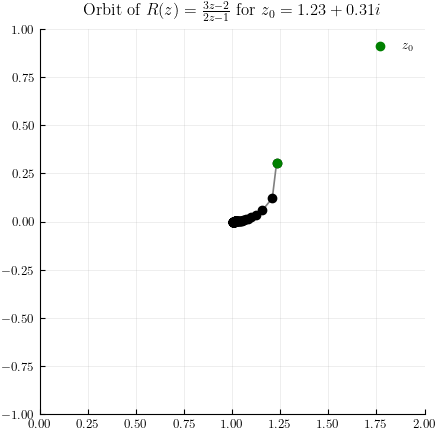

In [15]:
center = complex(1, 0)
max_distance_to_center = 1

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

title = rf"Orbit of $R(z) = \frac{{3z - 2}}{{2z - 1}}$ for $z_0 = {round(z0.real, 2)} + {round(z0.imag, 2)}i$"

fig, ax = dplot.plot_orbit(orbit)
ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

# Ejercicio 3

In [16]:
R = RationalMap.from_latex("2z/(z+1)")
print(R)

\frac{2 z}{z + 1}


Hemos analizado en papel que todas las iteraciones hacia atrás parten del $0$ ($(R^{-1})^n \to 0$) y hacia adelante llegan al $1$ ($R^n \to 1$). Así que voy a tomar puntos aleatorios cerca del $0$ (distancia de $0.1$ o menos en parte real e imaginaria, y veo cómo llegan al $1$). Para ver diferentes puntos iniciales ejecutar varias veces las celdas.

In [17]:
radius = 0.1
r_real = np.random.uniform(-radius, radius)
r_imag = np.random.uniform(-radius, radius)
r = complex(r_real, r_imag)
zeta = 0

z0 = np.complex128(zeta + r)

In [18]:
max_iterations = 100
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

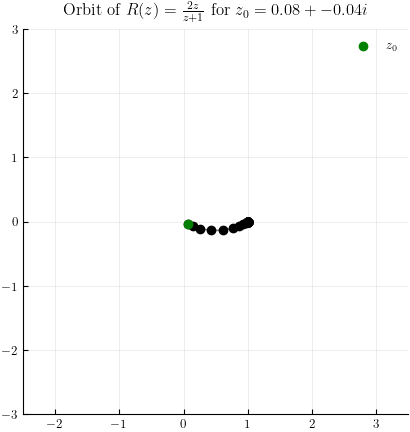

In [19]:
center = complex(0.5, 0)
max_distance_to_center = 3

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

title = rf"Orbit of $R(z) = \frac{{2z}}{{z + 1}}$ for $z_0 = {round(z0.real, 2)} + {round(z0.imag, 2)}i$"

fig, ax = dplot.plot_orbit(orbit)
ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

Por comodidad para ejecutar múltiples veces lo he juntado en una celda

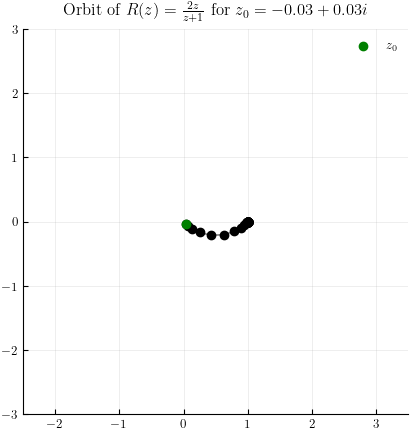

In [20]:
radius = 0.1
r_real = np.random.uniform(-radius, radius)
r_imag = np.random.uniform(-radius, radius)
r = complex(r_real, r_imag)
zeta = 0

z0 = np.complex128(zeta + r)

max_iterations = 100
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

center = complex(0.5, 0)
max_distance_to_center = 3

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

title = rf"Orbit of $R(z) = \frac{{2z}}{{z + 1}}$ for $z_0 = {round(z0.imag, 2)} + {round(z0.real, 2)}i$"

fig, ax = dplot.plot_orbit(orbit)
ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

# Ejercicio 4

In [21]:
R = RationalMap.from_latex("z/(2z+1)")
print(R)

\frac{z}{2 z + 1}


Hemos analizado en papel que tiene un punto fijo indiferente y es $0$. Además, todas las secuencias de iteraciones de R eventualmente convergen a $0$.

In [22]:
radius = 2
r_real = np.random.uniform(-radius, radius)
r_imag = np.random.uniform(-radius, radius)
r = complex(r_real, r_imag)
zeta = 0

z0 = np.complex128(zeta + r)

In [23]:
max_iterations = 100
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

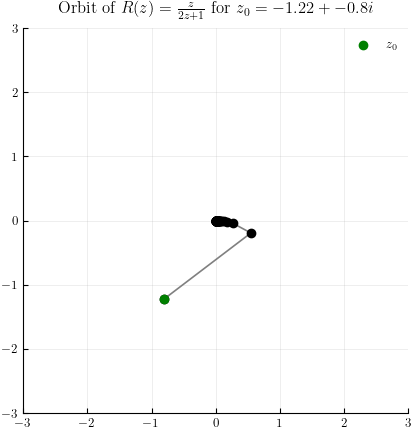

In [24]:
center = complex(0, 0)
max_distance_to_center = 3

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

title = rf"Orbit of $R(z) = \frac{{z}}{{2z + 1}}$ for $z_0 = {round(z0.imag, 2)} + {round(z0.real, 2)}i$"

fig, ax = dplot.plot_orbit(orbit)
ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

Por comodidad para ejecutar múltiples veces lo he juntado en una celda

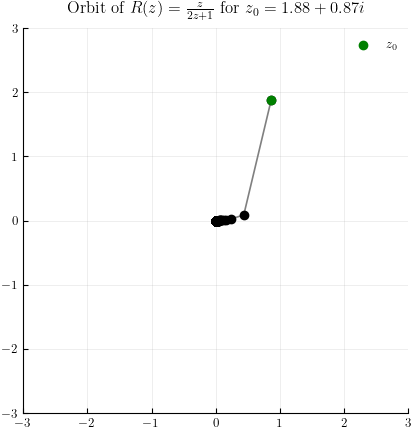

In [25]:
radius = 2
r_real = np.random.uniform(-radius, radius)
r_imag = np.random.uniform(-radius, radius)
r = complex(r_real, r_imag)
zeta = 0

z0 = np.complex128(zeta + r)

max_iterations = 1000
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

center = complex(0, 0)
max_distance_to_center = 3

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

title = rf"Orbit of $R(z) = \frac{{z}}{{2z + 1}}$ for $z_0 = {round(z0.imag, 2)} + {round(z0.real, 2)}i$"

fig, ax = dplot.plot_orbit(orbit)
ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

Hago más zoom para ver si se nota que $0$ es indiferente en convergencia más lenta o no se nota nada

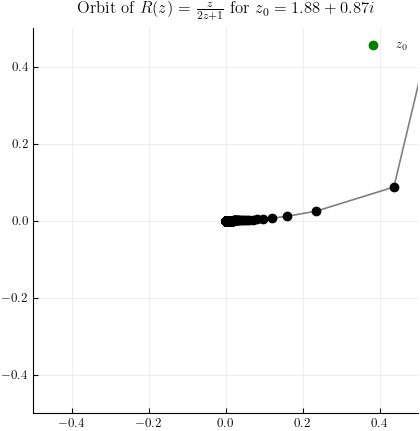

In [26]:
max_distance_to_center = 0.5

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig

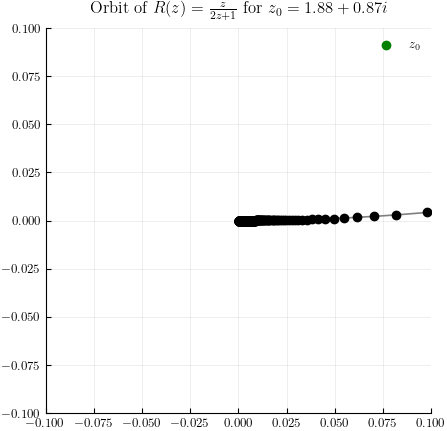

In [27]:
max_distance_to_center = 1e-1

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
fig

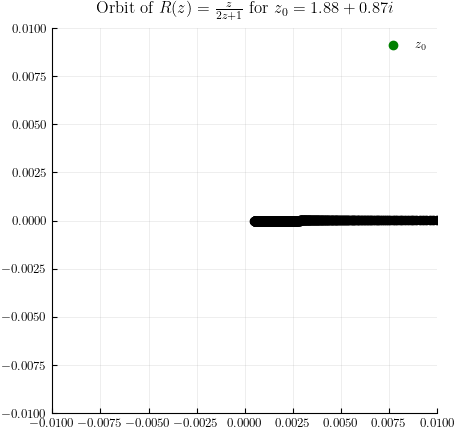

In [28]:
max_distance_to_center = 1e-2

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig

# Ejercicio 5

In [29]:
a = complex(1, 1)
b = complex(1, -1)

R = RationalMap(
    np.array([b, a], dtype=np.complex128), np.array([a, b], dtype=np.complex128)
)
print(R)

\frac{z \left(1 + i\right) + 1 - i}{z \left(1 - i\right) + 1 + i}


Hemos analizado en papel que tiene dos puntos fijos indiferentes, $1$ y $-1$. Además, todas las secuencias de iteraciones de R son cíclicas de grado 4 (menos las que empiezan en los puntos fijos, que son siempre el punto fijo).

In [30]:
radius = 2
r_real = np.random.uniform(-radius, radius)
r_imag = np.random.uniform(-radius, radius)
r = complex(r_real, r_imag)
zeta1 = 1
zeta2 = -1

z0 = np.complex128((zeta1 + zeta2) / 2 + r)

In [31]:
max_iterations = 4
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

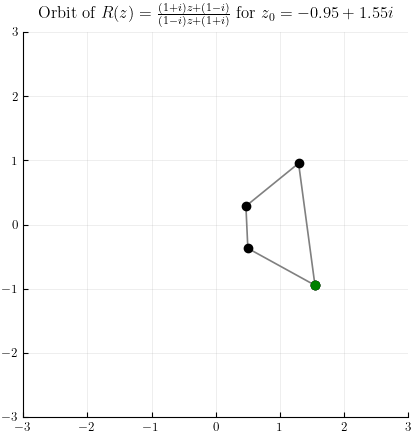

In [32]:
center = complex(0, 0)
max_distance_to_center = 3

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

title = rf"Orbit of $R(z) = \frac{{(1+i)z + (1-i)}}{{(1-i)z + (1+i)}}$ for $z_0 = {round(z0.imag, 2)} + {round(z0.real, 2)}i$"

fig, ax = dplot.plot_orbit(orbit)
ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)

Además, sabemos que todos los puntos de la secuencia caen en un círculo o recta, el siguiente código sirve para visualizarlo

In [33]:
def add_circle_to_plotter(z0, fig, ax):
    # Calculate and Plot the Apollonian Circle
    C = abs((z0 - 1) / (z0 + 1))

    # Check if the locus is a straight line (imaginary axis)
    if not np.isclose(C, 1.0):
        # Calculate mathematical center
        x_c = (1 + C**2) / (1 - C**2)
        c_circle = complex(x_c, 0)
        radius_circle = abs(z0 - c_circle)

        # Plot the circle center
        ax.scatter(
            c_circle.real,
            c_circle.imag,
            color="lightgray",
            marker="x",
            s=50,
            label="Circle Center",
            zorder=6,
        )

        # Draw the circle locus
        circle = plt.Circle(
            (c_circle.real, c_circle.imag),
            radius_circle,
            color="lightgray",
            fill=False,
            linestyle="--",
            linewidth=1.5,
            alpha=0.5,
            label="Apollonian Orbit Locus",
        )
        fig.gca().add_patch(circle)
    else:
        ax.axvline(
            0,
            color="lightgray",
            linestyle="--",
            label="Orbit Locus (Imaginary Axis)",
        )

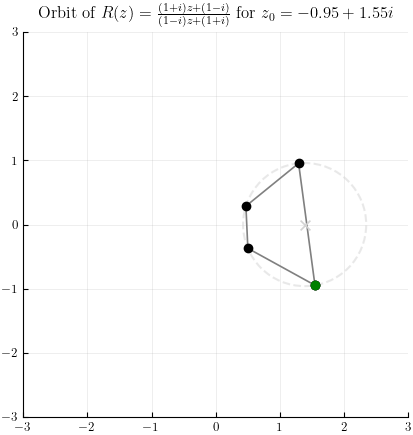

In [34]:
add_circle_to_plotter(z0, fig, ax)
fig

Por comodidad para ejecutar múltiples veces lo he juntado en una celda

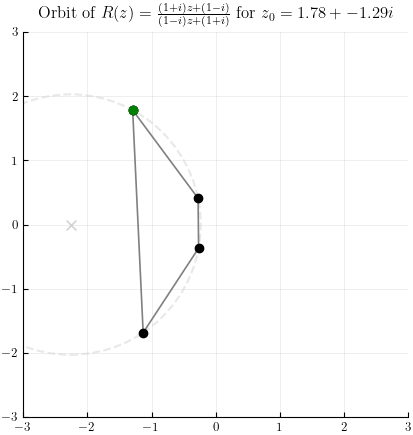

In [35]:
radius = 2
r_real = np.random.uniform(-radius, radius)
r_imag = np.random.uniform(-radius, radius)
r = complex(r_real, r_imag)
zeta1 = 1
zeta2 = -1

z0 = np.complex128((zeta1 + zeta2) / 2 + r)

max_iterations = 4
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

center = complex(0, 0)
max_distance_to_center = 3

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

title = rf"Orbit of $R(z) = \frac{{(1+i)z + (1-i)}}{{(1-i)z + (1+i)}}$ for $z_0 = {round(z0.imag, 2)} + {round(z0.real, 2)}i$"

fig, ax = dplot.plot_orbit(orbit)
ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
add_circle_to_plotter(z0, fig, ax)

Pruebo con puntos en el eje imaginario porque me ha salido una vez por azar y se ve que el ciclo puede ser en una recta

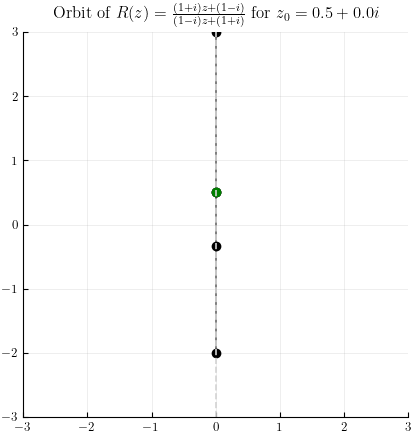

In [36]:
z0 = np.complex128(0.5j)

max_iterations = 4
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

center = complex(0, 0)
max_distance_to_center = 3

xmin = center.real - max_distance_to_center
xmax = center.real + max_distance_to_center
ymin = center.imag - max_distance_to_center
ymax = center.imag + max_distance_to_center

title = rf"Orbit of $R(z) = \frac{{(1+i)z + (1-i)}}{{(1-i)z + (1+i)}}$ for $z_0 = {round(z0.imag, 2)} + {round(z0.real, 2)}i$"

fig, ax = dplot.plot_orbit(orbit)
ax.set_title(title, pad=10)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(True)
add_circle_to_plotter(z0, fig, ax)

In [37]:
plotter = dplot.plot_orbit_on_dynamic_sphere(orbit, show=True)

Widget(value='<iframe src="http://localhost:40675/index.html?ui=P_0x7f2174ccc8e0_1&reconnect=auto" class="pyvi…

# Ejemplo propio con "ciclos infinitos"

Voy a coger la versión más sencilla: $R(z) = kz$, con un $k$ con módulo uno pero que no sea raíz de la unidad, es decir, que $k=\exp(\frac{i2\pi}{\omega})$ con $\omega$ irracional. En particular, tomo $\omega = \pi$.

In [38]:
theta = 2  # 2*np.pi/np.pi, es decir, la vuelta completa partida en pi trozos
k = 1 * np.exp(theta * 1j)

R = RationalMap.from_latex(rf"{k}z", imag_const="j")
print(R)

z \left(- \frac{7496634952020485}{18014398509481984} + \frac{4095111552621091 i}{4503599627370496}\right)


Hemos analizado en papel que tiene dos puntos fijos indiferentes. Además, todas las secuencias de iteraciones de R forman conjuntos densos en una circunferencia o línea.

In [39]:
radius = 2
r_real = np.random.uniform(-radius, radius)
r_imag = np.random.uniform(-radius, radius)
z0 = np.complex128(r_real + 1j * r_imag)

In [40]:
max_iterations = 100
orbit = dcalc.calculate_forward_orbit(z0, R, max_iterations=max_iterations)

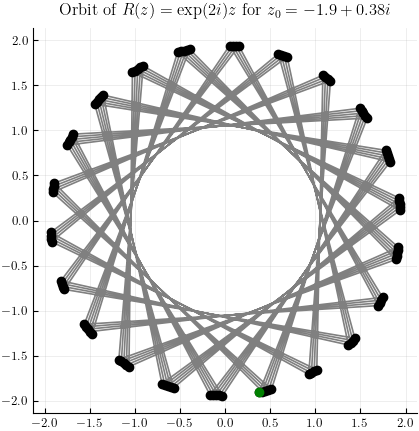

In [41]:
title = rf"Orbit of $R(z) = \exp(2i)z$ for $z_0 = {round(z0.imag, 2)} + {round(z0.real, 2)}i$"

fig, ax = dplot.plot_orbit(orbit)
ax.set_title(title, pad=10)
ax.set_aspect("equal")
ax.grid(True)

Por comodidad para ejecutar multiples veces lo he juntado en una celda

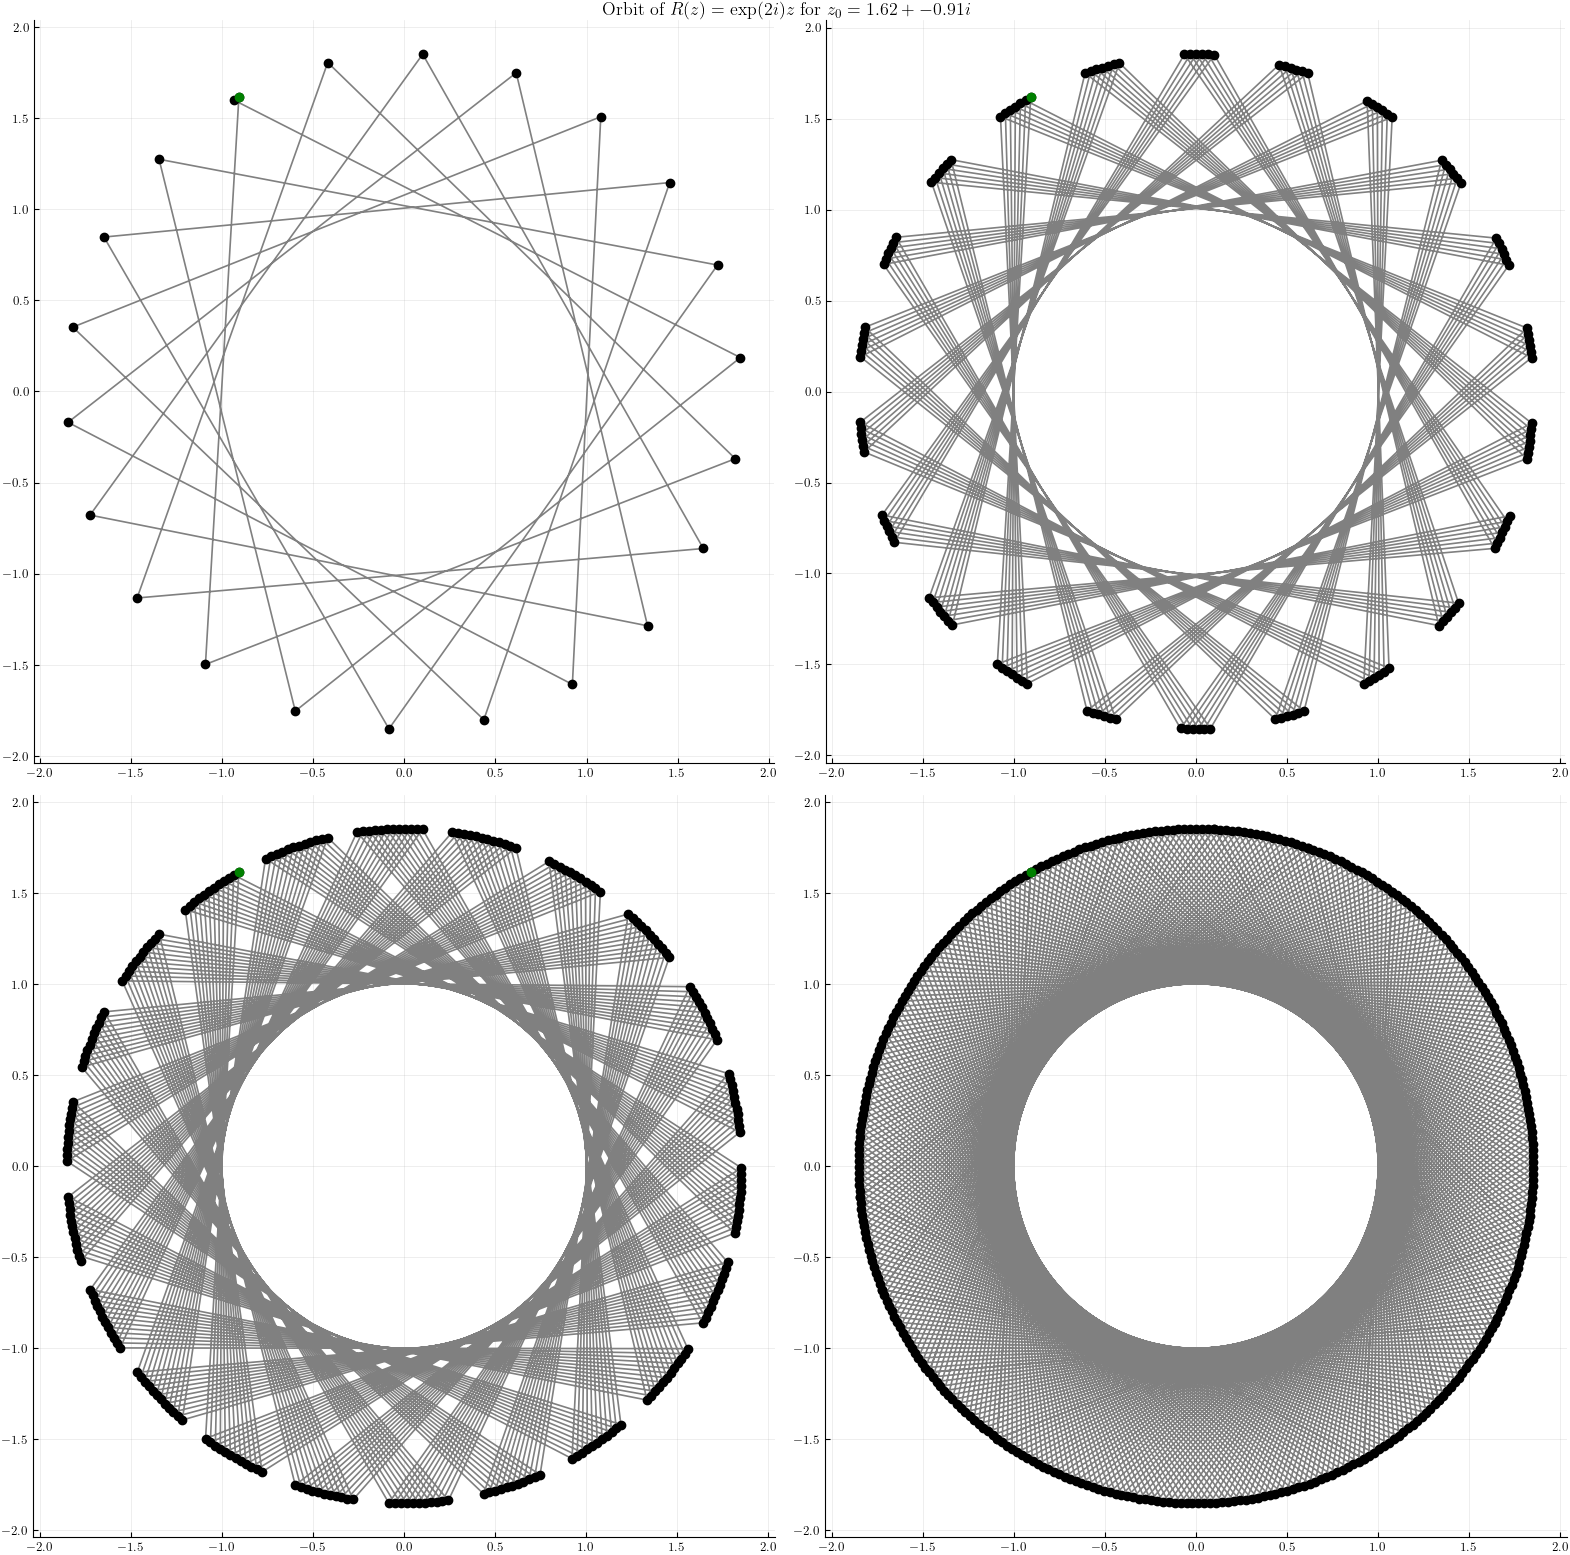

In [42]:
radius = 2
r_real = np.random.uniform(-radius, radius)
r_imag = np.random.uniform(-radius, radius)
z0 = np.complex128(r_real + 1j * r_imag)

title = rf"Orbit of $R(z) = \exp(2i)z$ for $z_0 = {round(z0.imag, 2)} + {round(z0.real, 2)}i$"

orbits = []
for i in range(4):
    orbits.append(
        dcalc.calculate_forward_orbit(z0, R, max_iterations=22 + 23 * 5 * i)
    )

fig = plt.figure(figsize=(16, 16))
axs2d = fig.subplots(2, 2)
fig.suptitle(title)
i = 0
for ax_row in axs2d:
    for ax in ax_row:
        dplot.plot_orbit(orbits[i], ax=ax)
        ax.set_aspect("equal")
        ax.grid(True)
        i += 1
plt.tight_layout()